In [ ]:
# STEP 1: Check the tools
import geopandas, rasterio, shapely
print("geopandas", geopandas.__version__)
print("rasterio", rasterio.__version__)
print("shapely", shapely.__version__)

geopandas 1.2.0
rasterio 1.5.2
shapely 2.1.2


In [ ]:
# STEP 2: Look up PCT IDs from BioNet
import requests, pandas as pd

URL = "https://data.bionet.nsw.gov.au/biosvcapp/odata/VegetationClassification_PCTDefinition"
searches = ["Black Cypress Pine - Red Stringybark", "Inland Scribbly Gum", "Canegrass",
            "Swamp Mahogany", "Southwest Ranges", "central and lower Hunter",
            "Red Ironbark - Narrow-leaved Ironbark - Grey Box"]

results = []
for s in searches:
    r = requests.get(URL, params={"$filter": f"contains(PCTName,'{s}')"}, timeout=60)
    for row in r.json().get("value", []):
        results.append({"search": s, "PCTID": row.get("PCTID"), "PCTName": row.get("PCTName")})

ids = pd.DataFrame(results)
pd.set_option("display.max_colwidth", 150)
ids

,search,PCTID,PCTName
0,Black Cypress Pine - Red Stringybark,309,Black Cypress Pine - Red Stringybark - red gum - box low open forest on siliceous rocky outcrops in the NSW South Western Slopes Bioregion
1,Black Cypress Pine - Red Stringybark,330,Mugga Ironbark - Black Cypress Pine - Red Stringybark - Blakely's Red Gum - Red Ironbark woodland on hillslopes and in valleys on ranges in the NS...
2,Black Cypress Pine - Red Stringybark,332,Tumbledown Red Gum - Black Cypress Pine - Red Stringybark woodland on rocky hills in the NSW central western slopes
3,Black Cypress Pine - Red Stringybark,339,Tumbledown Red Gum - Black Cypress Pine - Red Stringybark - Currawang shrubby low woodland on Wyangala granite and metasediments of the Wyangala D...
4,Black Cypress Pine - Red Stringybark,448,Smooth-barked Apple - Black Cypress Pine - Red Stringybark sandstone open forest in the Warialda to Arakoola region of the Brigalow Belt South Bio...
5,Inland Scribbly Gum,289,Mugga Ironbark - Inland Scribbly Gum - Red Box shrub/grass open forest on hills in the upper slopes sub-region of the NSW South Western Slopes Bio...
6,Inland Scribbly Gum,290,Red Stringybark - Red Box - Long-leaved Box - Inland Scribbly Gum tussock grass - shrub low open forest on hills in the southern part of the NSW S...
7,Inland Scribbly Gum,291,Inland Scribbly Gum - Black Cypress Pine - Mugga Ironbark - Daphne Heath low woodland of the Wagga Wagga region in the southern NSW South Western ...
8,Inland Scribbly Gum,322,Inland Scribbly Gum - Red Stringybark - Black Cypress Pine hillslope shrub-tussock grass open forest on mainly sandstone ranges in the NSW central...
9,Inland Scribbly Gum,323,Red Stringybark - Inland Scribbly Gum open forest on steep hills in the Mudgee - northern section of the NSW South Western Slopes Bioregion


In [ ]:
# STEP 3: Check status of our 7 PCT IDs
targets = [309, 290, 24, 4047, 1604, 3406, 1600]

r = requests.get(URL, params={"$filter": f"PCTID eq {targets[0]}"}, timeout=60)
print(list(r.json()["value"][0].keys()))

['institutionCode', 'collectionCode', 'datasetName', 'dcterms_rightsHolder', 'dcterms_rights', 'dcterms_language', 'dcterms_type', 'dcterms_bibliographicCitation', 'dcterms_modified', 'dcterms_available', 'PCTID', 'PCTName', 'PCTScientificName', 'status', 'classificationType', 'classificationConfidenceLevel', 'vegetationClass', 'vegetationClassID', 'vegetationFormation', 'vegetationFormationID', 'IBRA', 'IBRAID', 'IBRASubregion', 'IBRASubregionID', 'county', 'landscapeName', 'isADerivedPlantCommunityType', 'originalCommunityThisPCTDerivedFrom', 'derivedFromCommunityTypeComment', 'totalNumberOfReplicates', 'numberOfPrimaryReplicates', 'numberOfSecondaryReplicates', 'medianNativeSpeciesRichness', 'minimumElevationInMeters', 'medianElevationInMeters', 'maximumElevationInMeters', 'minimumAnnualRainfallInMillimeters', 'medianAnnualRainfallInMillimeters', 'maximumAnnualRainfallInMillimeters', 'minimumAnnualMeanTemperatureInCelsius', 'medianAnnualMeanTemperatureInCelsius', 'maximumAnnualMeanT

In [ ]:
# STEP 4: Key facts for our 7 PCTs
cols = ["PCTID", "PCTName", "status", "classificationType", "vegetationFormation",
        "IBRA", "PCTPercentCleared", "preEuropeanExtent", "currentExtent",
        "stateTECProfileID", "derivedFromCommunityTypeComment"]

rows = []
for t in targets:
    r = requests.get(URL, params={"$filter": f"PCTID eq {t}"}, timeout=60)
    rows += r.json()["value"]

facts = pd.DataFrame(rows)[cols]
facts.to_csv("pct_targets.csv", index=False)
facts

,PCTID,PCTName,status,classificationType,vegetationFormation,IBRA,PCTPercentCleared,preEuropeanExtent,currentExtent,stateTECProfileID,derivedFromCommunityTypeComment
0,309,Black Cypress Pine - Red Stringybark - red gum - box low open forest on siliceous rocky outcrops in the NSW South Western Slopes Bioregion,Approved,Qualitative,Dry Sclerophyll Forests (Shrubby sub-formation),NSW South Western Slopes,0.1500,20000.0,17000.0,None,None
1,290,Red Stringybark - Red Box - Long-leaved Box - Inland Scribbly Gum tussock grass - shrub low open forest on hills in the southern part of the NSW S...,Approved,Qualitative,Dry Sclerophyll Forests (Shrub/grass sub-formation),NSW South Western Slopes,0.6700,30000.0,10000.0,None,None
2,24,"Canegrass swamp tall grassland wetland of drainage depressions, lakes and pans of the inland plains",Approved,Qualitative,Freshwater Wetlands,Broken Hill Complex;Mulga Lands;Channel Country;Murray Darling Depression;Simpson Strzelecki Dunefields;Darling Riverine Plains;Riverina;Brigalow ...,0.2000,500000.0,400000.0,10065,None
3,4047,Northern Swamp Mahogany-Bottlebrush Swamp Forest,Approved,Quantitative,Forested Wetlands,NSW North Coast;South Eastern Queensland;Sydney Basin,0.3263,7080.0,4770.0,10786,None
4,1604,Narrow-leaved Ironbark - Grey Box - Spotted Gum shrub - grass woodland of the central and lower Hunter,Approved,Qualitative,Grassy Woodlands,Brigalow Belt South,0.7100,NaN,NaN,20127,None
5,3406,Southwest Ranges White Box Woodland,Approved,Quantitative,Grassy Woodlands,NSW South Western Slopes;South Eastern Highlands;Sydney Basin,0.8873,243637.0,27462.0,10837,None
6,1600,Spotted Gum - Red Ironbark - Narrow-leaved Ironbark - Grey Box shrub-grass open forest of the lower Hunter,Decommissioned,Qualitative,Dry Sclerophyll Forests (Shrub/grass sub-formation),NSW North Coast;Sydney Basin,0.7100,0.0,0.0,"10942,20127",None


In [ ]:
# STEP 5: List BioNet tables to find the old-to-new PCT lookup
base = "https://data.bionet.nsw.gov.au/biosvcapp/odata/"
names = [e["name"] for e in requests.get(base, timeout=60).json()["value"]]
[n for n in names if "PCT" in n or "Veg" in n or "Cross" in n]

['VegetationClassification_PCTDefinition',
 'VegetationClassification_PCTBenchmarks',
 'VegetationClassification_PCTStratumData',
 'VegetationClassification_PCTGrowthForm']

In [ ]:
# STEP 6: Final target list (drop retired PCT 1600)
targets = [309, 290, 24, 4047, 1604, 3406]
facts = facts[facts["PCTID"].isin(targets)]
facts.to_csv("pct_targets.csv", index=False)
print(len(facts), "target PCTs saved")

6 target PCTs saved


In [ ]:
# STEP 7: Download IBRA v7.1 subregions (DCCEEW)
import geopandas as gpd

ibra_url = "https://fed.dcceew.gov.au/api/download/v1/items/38e668537a2141be85b8418ac8b6f3ed/shapefile?layers=0"
!wget -q -O ibra.zip "{ibra_url}"
ibra = gpd.read_file("ibra.zip")
print(ibra.shape)
print(ibra.columns.tolist())
print(ibra.crs)

(419, 9)
['OBJECTID', 'SUB_CODE_7', 'SUB_NAME_7', 'REG_CODE_7', 'REG_NAME_7', 'HECTARES', 'SHAPE_Leng', 'SHAPE_Area', 'geometry']
EPSG:3857


137 subregions in NSW


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

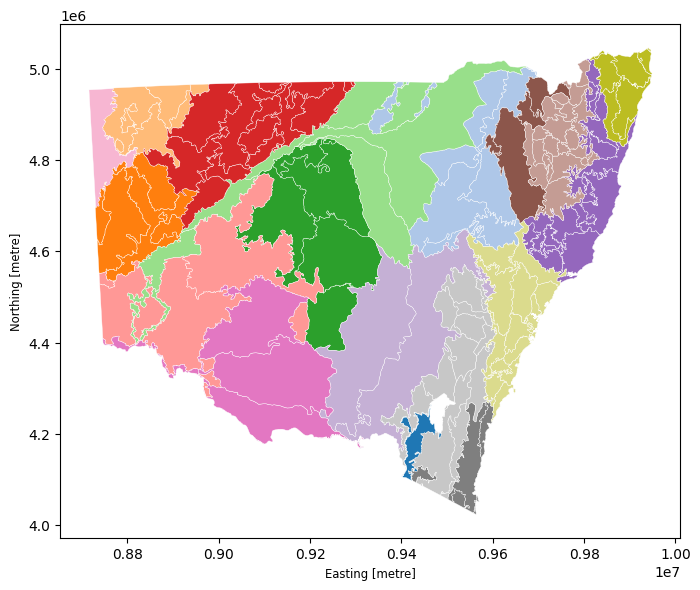

In [ ]:
# STEP 8: Clip IBRA to NSW and reproject to NSW Lambert
ne_url = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_1_states_provinces.zip"
!wget -q -O states.zip "{ne_url}"
states = gpd.read_file("states.zip")
nsw = states[states["name"] == "New South Wales"].to_crs(3308)

ibra = ibra.to_crs(3308)
ibra_nsw = gpd.clip(ibra, nsw)
ibra_nsw["area_ha"] = ibra_nsw.area / 10_000

print(len(ibra_nsw), "subregions in NSW")
ibra_nsw.plot(column="REG_NAME_7", figsize=(8, 8), edgecolor="white", linewidth=0.3)

In [ ]:
# STEP 9: Drop tiny border slivers and save NSW subregions
ibra["full_ha"] = ibra.area / 10_000
ibra_nsw = ibra_nsw.merge(ibra[["SUB_CODE_7", "full_ha"]], on="SUB_CODE_7")
ibra_nsw["share_in_nsw"] = ibra_nsw["area_ha"] / ibra_nsw["full_ha"]

slivers = ibra_nsw[(ibra_nsw["share_in_nsw"] < 0.01) & (ibra_nsw["area_ha"] < 5000)]
print("Dropped:", slivers["SUB_NAME_7"].tolist())

ibra_nsw = ibra_nsw.drop(slivers.index)
ibra_nsw.to_file("ibra_nsw.gpkg")
print(len(ibra_nsw), "NSW subregions saved")

Dropped: ['Moonie-Commoron Floodout', 'Sunshine Coast-Gold Coast Lowlands', 'Eastern Darling Downs', 'Murray Mallee', 'Highlands-Northern Fall']
132 NSW subregions saved


In [ ]:
# STEP 10: Save work to Google Drive
from google.colab import drive
drive.mount("/content/drive")

import os, shutil
PROJ = "/content/drive/MyDrive/nsw-credit-opportunity-map"
for d in ["data/raw", "data/processed", "outputs/maps"]:
    os.makedirs(f"{PROJ}/{d}", exist_ok=True)

shutil.copy("pct_targets.csv", f"{PROJ}/data/processed/")
shutil.copy("ibra_nsw.gpkg", f"{PROJ}/data/processed/")
os.chdir(PROJ)
print(os.listdir("data/processed"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['pct_targets.csv', 'ibra_nsw.gpkg', 'remnant_by_subregion.csv']


In [ ]:
# STEP 11: Download SVTM C2.0M2.2 to Colab's local disk
!df -h /content | tail -1
svtm_url = "https://datasets.seed.nsw.gov.au/dataset/95437fbd-2ef7-44df-8579-d7a64402d42d/resource/0994aef6-89db-44a5-b70a-9434d920dc06/download/svtm_nsw_extant_pct_vc2_0_m2_2_108.zip"
!wget -c -q --show-progress -O /content/svtm.zip "{svtm_url}"
!ls -lh /content/svtm.zip

overlay         108G   21G   87G  20% /
/content/svtm.zip       [ <=>                ]       0  --.-KB/s    in 0s      
-rw-r--r-- 1 root root 0 Oct 10 21:40 /content/svtm.zip


In [ ]:
# STEP 11b: See what the server replies
!wget -S --spider "{svtm_url}" 2>&1 | head -25

Spider mode enabled. Check if remote file exists.
--2026-10-10 23:13:54--  https://datasets.seed.nsw.gov.au/dataset/95437fbd-2ef7-44df-8579-d7a64402d42d/resource/0994aef6-89db-44a5-b70a-9434d920dc06/download/svtm_nsw_extant_pct_vc2_0_m2_2_108.zip
Resolving datasets.seed.nsw.gov.au (datasets.seed.nsw.gov.au)... 18.172.170.68, 18.172.170.2, 18.172.170.18, ...
Connecting to datasets.seed.nsw.gov.au (datasets.seed.nsw.gov.au)|18.172.170.68|:443... connected.
HTTP request sent, awaiting response... 
  HTTP/1.1 202 Accepted
  Server: CloudFront
  Date: Sat, 10 Oct 2026 23:13:54 GMT
  Content-Length: 0
  Connection: keep-alive
  x-amzn-waf-action: challenge
  Cache-Control: no-store, max-age=0
  Content-Type: text/html; charset=UTF-8
  Access-Control-Allow-Origin: *
  Access-Control-Max-Age: 86400
  Access-Control-Allow-Methods: OPTIONS,GET,POST
  Access-Control-Expose-Headers: x-amzn-waf-action
  X-Cache: Error from cloudfront
  Via: 1.1 99e59f379d63394e88e658d91cfc7d4c.cloudfront.net (Cloud

In [ ]:
# STEP 11c: Inspect the SVTM map service
svc = "https://mapprod3.environment.nsw.gov.au/arcgis/rest/services/VIS/SVTM_NSW_Extant_PCT/MapServer"
info = requests.get(svc, params={"f": "json"}, timeout=60).json()
print("Capabilities:", info.get("capabilities"))
print("Max records:", info.get("maxRecordCount"))
for lyr in info.get("layers", []):
    print(lyr["id"], lyr["name"], lyr.get("type", ""))

Capabilities: Map,Query,Data
Max records: 1000
0 NSW_VegetationFormation_5m Raster Layer
1 NSW_VegetationClass_5m Raster Layer
2 NSW_PlantCommunityType_5m Raster Layer
3 Plant Community Type with labels Feature Layer


In [ ]:
# STEP 11d: Fields in the PCT feature layer
lyr = requests.get(f"{svc}/3", params={"f": "json"}, timeout=60).json()
print("Geometry:", lyr.get("geometryType"), "| SR:", lyr.get("extent", {}).get("spatialReference"))
print("Min scale:", lyr.get("minScale"))
for f in lyr.get("fields", []):
    print(f["name"], f["type"])

Geometry: esriGeometryPolygon | SR: {'wkid': 3308, 'latestWkid': 3308}
Min scale: 25000
OBJECTID esriFieldTypeOID
Shape esriFieldTypeGeometry
PCTID esriFieldTypeInteger
PCTName esriFieldTypeString
vegClass esriFieldTypeString
vegForm esriFieldTypeString
form_PCT esriFieldTypeString
labels esriFieldTypeString
PCT_form esriFieldTypeString
Shape_Length esriFieldTypeDouble
Shape_Area esriFieldTypeDouble


In [ ]:
# STEP 11e: Count polygons and hectares per target PCT
q = f"{svc}/3/query"
where = f"PCTID IN ({','.join(map(str, targets))})"

stats = [{"statisticType": "count", "onStatisticField": "OBJECTID", "outStatisticFieldName": "n"},
         {"statisticType": "sum", "onStatisticField": "Shape_Area", "outStatisticFieldName": "m2"}]
import json
r = requests.get(q, params={"where": where, "groupByFieldsForStatistics": "PCTID",
                            "outStatistics": json.dumps(stats), "f": "json"}, timeout=120).json()

summary = pd.DataFrame([f["attributes"] for f in r.get("features", [])])
summary["hectares"] = (summary["m2"] / 10_000).round(0)
summary

,PCTID,n,m2,hectares
0,24,72883,7.906575e+09,790658.0
1,290,13267,4.286546e+08,42865.0
2,309,487,7.424155e+07,7424.0
3,3406,16040,1.498874e+08,14989.0
4,4047,2329,4.745735e+07,4746.0
5,1604,3,4.512500e+04,5.0


In [ ]:
# STEP 12: Download target PCT polygons in pages of 1000
def fetch_pct(pct):
    parts, offset = [], 0
    while True:
        r = requests.get(q, params={"where": f"PCTID = {pct}", "outFields": "PCTID,PCTName",
                                    "resultOffset": offset, "resultRecordCount": 1000,
                                    "outSR": 3308, "f": "geojson"}, timeout=300)
        page = gpd.read_file(r.text)
        if page.empty:
            break
        parts.append(page)
        offset += len(page)
    gdf = pd.concat(parts, ignore_index=True).set_crs(3308, allow_override=True)
    gdf.to_file("data/raw/svtm_targets.gpkg", layer=f"pct_{pct}")
    print(pct, len(gdf), "polygons saved")

for pct in [309, 4047, 1604, 3406, 290, 24]:
    fetch_pct(pct)

309 487 polygons saved
4047 2329 polygons saved
1604 3 polygons saved
3406 16040 polygons saved
290 13267 polygons saved
24 72883 polygons saved


       polygons  hectares
PCTID                    
24        72883  790658.0
290       13267   42865.0
309         487    7424.0
1604          3       5.0
3406      16040   14989.0
4047       2329    4746.0


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

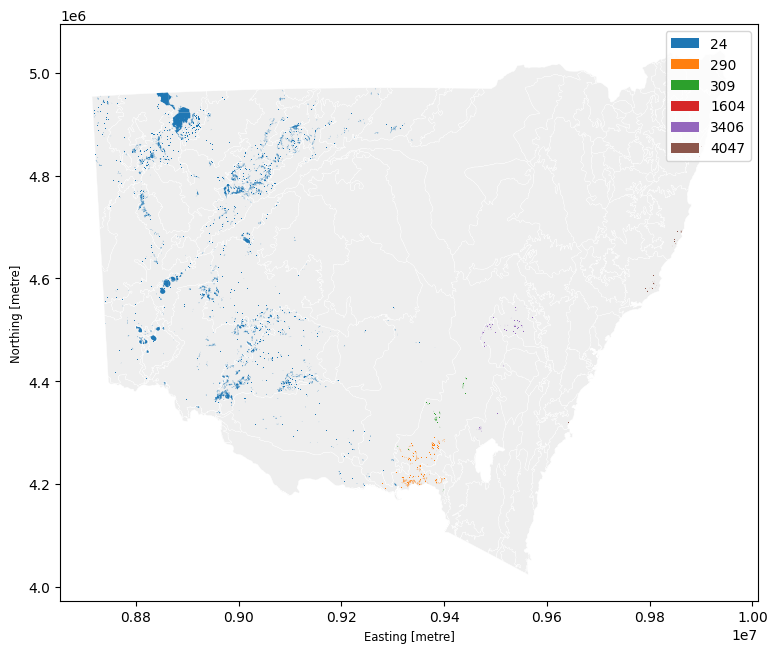

In [ ]:
# STEP 13: Load all target PCTs into one layer and check totals
layers = gpd.list_layers("data/raw/svtm_targets.gpkg")["name"].tolist()
veg = pd.concat([gpd.read_file("data/raw/svtm_targets.gpkg", layer=l) for l in layers],
                ignore_index=True).set_crs(3308, allow_override=True)
veg["ha"] = veg.area / 10_000

print(veg.groupby("PCTID").agg(polygons=("ha", "size"), hectares=("ha", "sum")).round(0))

ax = ibra_nsw.plot(color="#eeeeee", edgecolor="white", linewidth=0.3, figsize=(9, 9))
veg.plot(ax=ax, column="PCTID", categorical=True, legend=True)

In [ ]:
# STEP 14: Overlay vegetation with IBRA subregions
veg["geometry"] = veg.geometry.make_valid()
sub = ibra_nsw[["SUB_CODE_7", "SUB_NAME_7", "REG_NAME_7", "geometry"]]

pieces = gpd.overlay(veg[["PCTID", "geometry"]], sub, how="intersection", keep_geom_type=True)
pieces["ha"] = pieces.area / 10_000

by_sub = (pieces.groupby(["PCTID", "REG_NAME_7", "SUB_NAME_7"])["ha"].sum()
          .round(0).reset_index().sort_values(["PCTID", "ha"], ascending=[True, False]))
by_sub.to_csv("data/processed/remnant_by_subregion.csv", index=False)

print(len(by_sub), "PCT x subregion rows")
by_sub.groupby("PCTID").head(3)

73 PCT x subregion rows


,PCTID,REG_NAME_7,SUB_NAME_7,ha
6,24,Channel Country,Bulloo,155745.0
40,24,Riverina,Lachlan,133889.0
28,24,Mulga Lands,Paroo Overflow,59015.0
47,290,NSW South Western Slopes,Inland Slopes,42847.0
48,290,NSW South Western Slopes,Lower Slopes,5.0
49,290,South Eastern Highlands,Bondo,0.0
50,309,NSW South Western Slopes,Inland Slopes,7337.0
51,309,NSW South Western Slopes,Lower Slopes,87.0
52,1604,Brigalow Belt South,Liverpool Range,5.0
59,3406,South Eastern Highlands,Hill End,6639.0


In [ ]:
# STEP 15: List vegetation map services to find the pre-clearing map
folder = "https://mapprod3.environment.nsw.gov.au/arcgis/rest/services/VIS"
services = requests.get(folder, params={"f": "json"}, timeout=60).json()["services"]
[s["name"] for s in services if "SVTM" in s["name"] or "Pre" in s["name"]]

['VIS/SVTM_NSW_1750_PCT',
 'VIS/SVTM_NSW_Extant_PCT',
 'VIS/SVTM_NSW_PCT_TNM_50M',
 'VIS/Vegetation_SVTM_BRGNSVM_v2p0_Raster5m_PCT_E_4467',
 'VIS/Vegetation_SVTM_CWLSVM_v1p4_Raster5m_PCT_E_4468',
 'VIS/Vegetation_SVTM_RiverinaSVM_v1p2_Raster5m_PCT_E_4469',
 'VIS/Vegetation_SVTM_UpperHunter_v1',
 'VIS/Vegetation_SVTM_Western_v1']

In [ ]:
# STEP 16: Pre-clearing (1750) service: find feature layer and count target PCTs
svc1750 = "https://mapprod3.environment.nsw.gov.au/arcgis/rest/services/VIS/SVTM_NSW_1750_PCT/MapServer"
info = requests.get(svc1750, params={"f": "json"}, timeout=60).json()
for lyr in info.get("layers", []):
    print(lyr["id"], lyr["name"], lyr.get("type", ""))

fl = [l["id"] for l in info["layers"] if l.get("type") == "Feature Layer"][0]
q1750 = f"{svc1750}/{fl}/query"
r = requests.get(q1750, params={"where": where, "groupByFieldsForStatistics": "PCTID",
                                "outStatistics": json.dumps(stats), "f": "json"}, timeout=120).json()
pre = pd.DataFrame([f["attributes"] for f in r.get("features", [])])
pre["hectares_1750"] = (pre["m2"] / 10_000).round(0)
pre

0 NSW_VegetationFormation_5m Raster Layer
1 NSW_VegetationClass_5m Raster Layer
2 NSW_PlantCommunityType_5m Raster Layer
3 Plant Community Type with labels Feature Layer


,PCTID,n,m2,hectares_1750
0,309,456,7.476175e+07,7476.0
1,290,7337,4.541868e+08,45419.0
2,24,71016,8.099633e+09,809963.0
3,3406,5620,3.987794e+08,39878.0
4,4047,1080,7.184137e+07,7184.0
5,1604,3,4.312500e+04,4.0


In [ ]:
# STEP 16: Pre-clearing (1750) service: find feature layer and count target PCTs
svc1750 = "https://mapprod3.environment.nsw.gov.au/arcgis/rest/services/VIS/SVTM_NSW_1750_PCT/MapServer"
info = requests.get(svc1750, params={"f": "json"}, timeout=60).json()
for lyr in info.get("layers", []):
    print(lyr["id"], lyr["name"], lyr.get("type", ""))

fl = [l["id"] for l in info["layers"] if l.get("type") == "Feature Layer"][0]
q1750 = f"{svc1750}/{fl}/query"
r = requests.get(q1750, params={"where": where, "groupByFieldsForStatistics": "PCTID",
                                "outStatistics": json.dumps(stats), "f": "json"}, timeout=120).json()
pre = pd.DataFrame([f["attributes"] for f in r.get("features", [])])
pre["hectares_1750"] = (pre["m2"] / 10_000).round(0)
pre

0 NSW_VegetationFormation_5m Raster Layer
1 NSW_VegetationClass_5m Raster Layer
2 NSW_PlantCommunityType_5m Raster Layer
3 Plant Community Type with labels Feature Layer


,PCTID,n,m2,hectares_1750
0,309,456,7.476175e+07,7476.0
1,290,7337,4.541868e+08,45419.0
2,24,71016,8.099633e+09,809963.0
3,3406,5620,3.987794e+08,39878.0
4,4047,1080,7.184137e+07,7184.0
5,1604,3,4.312500e+04,4.0


In [ ]:
# STEP 17: Download CAPAD 2024 terrestrial protected areas and keep NSW
capad_url = "https://fed.dcceew.gov.au/api/download/v1/items/ec356a872d8048459fe78fc80213dc70/shapefile?layers=0"
!wget -q -O /content/capad.zip "{capad_url}"
capad = gpd.read_file("/content/capad.zip")
print(capad.shape)
print(capad.columns.tolist())

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received an unexpected geometry.  Either a polygon with interior rings, or a polygon with less than 4 points, or a non-Polygon geometry.  Return arguments as a collection.
  return ogr_read(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Geometry of polygon of fid 5897 cannot be translated to Simple Geometry. All polygons will be contained in a multipolygon.
  return ogr_read(


(14492, 30)
['OBJECTID', 'PA_ID', 'PA_PID', 'NAME', 'TYPE', 'TYPE_ABBR', 'IUCN', 'NRS_PA', 'NRS_MPA', 'GAZ_AREA', 'GIS_AREA', 'GAZ_DATE', 'LATEST_GAZ', 'STATE', 'AUTHORITY', 'DATASOURCE', 'GOVERNANCE', 'COMMENTS', 'ENVIRON', 'OVERLAP', 'MGT_PLAN', 'RES_NUMBER', 'ZONE_TYPE', 'EPBC', 'LONGITUDE', 'LATITUDE', 'PA_SYSTEM', 'Shape__Are', 'Shape__Len', 'geometry']


In [1]:
# STEP R: Reload after restart
import os, json, time, shutil, requests, numpy as np, pandas as pd, geopandas as gpd, shapely
from google.colab import drive
drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive/nsw-credit-opportunity-map")

ibra_nsw = gpd.read_file("data/processed/ibra_nsw.gpkg")
layers = gpd.list_layers("data/raw/svtm_targets.gpkg")["name"].tolist()
veg = pd.concat([gpd.read_file("data/raw/svtm_targets.gpkg", layer=l) for l in layers],
                ignore_index=True).set_crs(3308, allow_override=True)
veg["geometry"] = veg.geometry.make_valid()
print("veg loaded:", len(veg))

sub = ibra_nsw[["SUB_CODE_7", "SUB_NAME_7", "REG_NAME_7", "geometry"]]
pieces = gpd.overlay(veg[["PCTID", "geometry"]], sub, how="intersection", keep_geom_type=True)
pieces["ha"] = pieces.area / 10_000
pieces.to_file("data/processed/pieces.gpkg")
by_sub = (pieces.groupby(["PCTID", "REG_NAME_7", "SUB_NAME_7"])["ha"].sum()
          .round(0).reset_index().sort_values(["PCTID", "ha"], ascending=[True, False]))
print("pieces:", len(pieces), "| rows:", len(by_sub))

if not os.path.exists("/content/capad.zip"):
    !wget -q -O /content/capad.zip "https://fed.dcceew.gov.au/api/download/v1/items/ec356a872d8048459fe78fc80213dc70/shapefile?layers=0"
capad = gpd.read_file("/content/capad.zip")
capad_nsw = capad[capad["STATE"] == "NSW"].to_crs(3308)
capad_nsw["geometry"] = capad_nsw.geometry.make_valid()
print("NSW protected areas:", len(capad_nsw))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
veg loaded: 105009
pieces: 106176 | rows: 73


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received an unexpected geometry.  Either a polygon with interior rings, or a polygon with less than 4 points, or a non-Polygon geometry.  Return arguments as a collection.
  return ogr_read(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Geometry of polygon of fid 5897 cannot be translated to Simple Geometry. All polygons will be contained in a multipolygon.
  return ogr_read(


NSW protected areas: 1018


In [2]:
# STEP 18 (v3): Protected area per piece using a spatial index (no dissolve)
import shapely, numpy as np, time
t0 = time.time()
pieces = pieces.reset_index(drop=True)
pa = capad_nsw[["geometry"]].reset_index(drop=True)

pairs = gpd.sjoin(pieces[["geometry"]], pa, predicate="intersects", how="inner")
print(len(pairs), "piece-park overlaps found", f"({time.time()-t0:.0f}s)")

a = np.asarray(pieces.geometry.values[pairs.index])
b = np.asarray(pa.geometry.values[pairs["index_right"].values])
pairs["prot_m2"] = shapely.area(shapely.intersection(a, b))
print("overlaps measured", f"({time.time()-t0:.0f}s)")

per_piece = pairs.groupby(level=0)["prot_m2"].sum()
pieces["prot_ha"] = np.minimum(per_piece.reindex(pieces.index).fillna(0), pieces.area) / 10_000

prot_sum = pieces.groupby(["PCTID", "SUB_NAME_7"])["prot_ha"].sum().reset_index()
by_sub = by_sub.drop(columns=["prot_ha", "unprot_ha", "pct_protected"], errors="ignore")
by_sub = by_sub.merge(prot_sum, on=["PCTID", "SUB_NAME_7"], how="left").fillna({"prot_ha": 0})
by_sub["unprot_ha"] = (by_sub["ha"] - by_sub["prot_ha"]).clip(lower=0).round(0)
by_sub["pct_protected"] = (100 * by_sub["prot_ha"] / by_sub["ha"]).round(1)
by_sub.to_csv("data/processed/remnant_by_subregion.csv", index=False)

by_sub.groupby("PCTID")[["ha", "prot_ha", "unprot_ha"]].sum().round(0)

4387 piece-park overlaps found (3s)
overlaps measured (5s)


,ha,prot_ha,unprot_ha
PCTID,,,
24,790654.0,77216.0,713439.0
290,42852.0,9877.0,32975.0
309,7424.0,2860.0,4564.0
1604,5.0,0.0,5.0
3406,14988.0,91.0,14897.0
4047,4746.0,2121.0,2625.0


In [3]:
# STEP 19: Score and rank subregions
demand = {309: 507, 290: 289, 24: 155, 4047: 153, 1604: 137, 3406: 127}   # retired/yr
pct = pd.read_csv("data/processed/pct_targets.csv")
cleared = dict(zip(pct["PCTID"], pct["PCTPercentCleared"]))

s = by_sub[by_sub["unprot_ha"] >= 10].copy()                     # ignore tiny slivers
s["share"] = s["unprot_ha"] / s.groupby("PCTID")["unprot_ha"].transform("sum")
s["demand"] = s["PCTID"].map(demand)
s["cleared"] = s["PCTID"].map(cleared)
s["score"] = s["share"] * s["demand"] * (1 + s["cleared"])

rank = (s.groupby(["REG_NAME_7", "SUB_NAME_7"])
          .agg(score=("score", "sum"), unprot_ha=("unprot_ha", "sum"),
               pcts=("PCTID", lambda x: ", ".join(map(str, sorted(x)))))
          .sort_values("score", ascending=False).reset_index())
rank["rank"] = range(1, len(rank) + 1)
rank["score"] = rank["score"].round(1)
rank.to_csv("data/processed/subregion_ranking.csv", index=False)
rank.head(10)

,REG_NAME_7,SUB_NAME_7,score,unprot_ha,pcts,rank
0,NSW South Western Slopes,Inland Slopes,1056.6,38842.0,"24, 290, 309, 3406",1
1,NSW North Coast,Macleay Hastings,127.0,1632.0,4047,2
2,South Eastern Highlands,Hill End,106.6,6623.0,3406,3
3,South Eastern Highlands,Orange,91.3,5676.0,3406,4
4,NSW North Coast,Karuah Manning,51.2,658.0,4047,5
5,Riverina,Lachlan,34.8,133594.0,24,6
6,South Eastern Highlands,Murrumbateman,30.8,1916.0,3406,7
7,Channel Country,Bulloo,27.3,104675.0,24,8
8,NSW North Coast,Coffs Coast and Escarpment,16.0,205.0,4047,9
9,Mulga Lands,Paroo Overflow,13.6,52175.0,24,10


In [4]:
# STEP 20: Does the top 5 change if we weight things differently?
def top5(score_col):
    r = s.groupby("SUB_NAME_7")[score_col].sum().sort_values(ascending=False)
    return list(r.head(5).index)

s["score_no_threat"] = s["share"] * s["demand"]                 # ignore % cleared
s["score_no_demand"] = s["share"] * (1 + s["cleared"]) * 100    # ignore demand
s["score_equal"]     = s["share"] * 100                         # every PCT counts the same

for col in ["score", "score_no_threat", "score_no_demand", "score_equal"]:
    print(f"{col:16}", top5(col))

score            ['Inland Slopes', 'Macleay Hastings', 'Hill End', 'Orange', 'Karuah Manning']
score_no_threat  ['Inland Slopes', 'Macleay Hastings', 'Hill End', 'Orange', 'Karuah Manning']
score_no_demand  ['Inland Slopes', 'Hill End', 'Macleay Hastings', 'Orange', 'Karuah Manning']
score_equal      ['Inland Slopes', 'Macleay Hastings', 'Hill End', 'Orange', 'Karuah Manning']


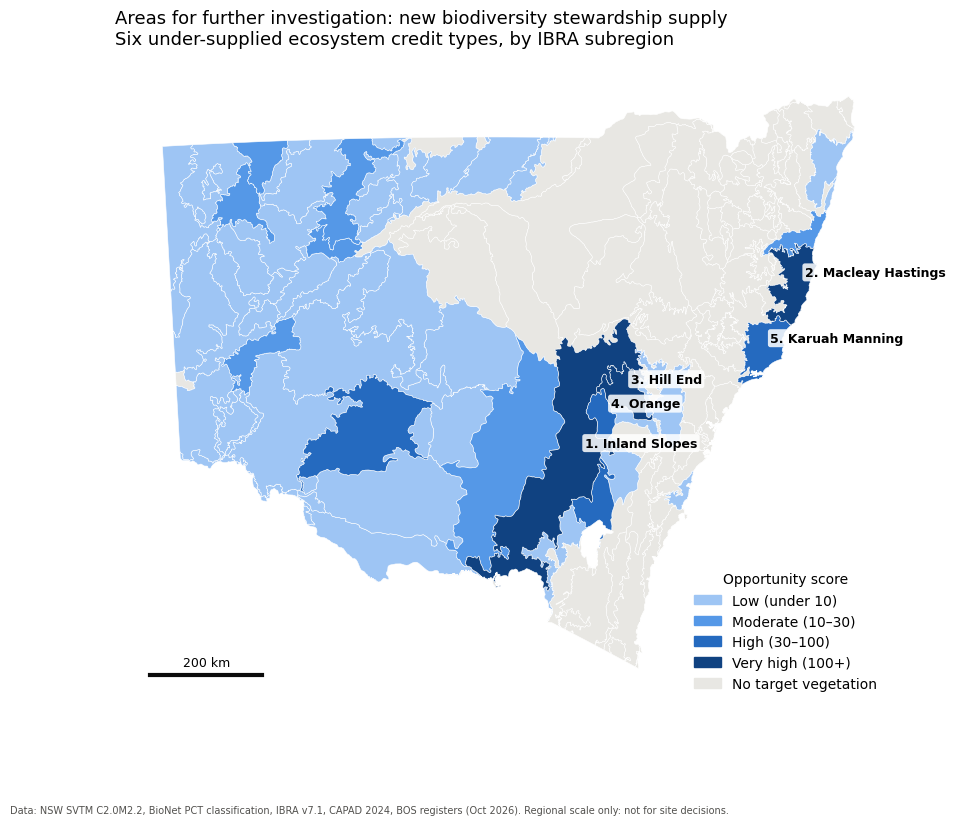

In [5]:
# STEP 21: Map 1 - statewide overview of areas for further investigation
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
os.makedirs("outputs/maps", exist_ok=True)

m = ibra_nsw.merge(rank[["SUB_NAME_7", "score", "rank"]], on="SUB_NAME_7", how="left")
bins   = [0, 10, 30, 100, 1e9]
labels = ["Low (under 10)", "Moderate (10–30)", "High (30–100)", "Very high (100+)"]
ramp   = ["#9ec5f4", "#5598e7", "#256abf", "#104281"]
m["cls"] = pd.cut(m["score"], bins=bins, labels=labels)

fig, ax = plt.subplots(figsize=(10, 9))
m[m["cls"].isna()].plot(ax=ax, color="#e8e7e3", edgecolor="white", linewidth=0.4)
for lab, col in zip(labels, ramp):
    m[m["cls"] == lab].plot(ax=ax, color=col, edgecolor="white", linewidth=0.4)

for _, r in m[m["rank"] <= 5].iterrows():
    p = r.geometry.representative_point()
    ax.annotate(f"{int(r['rank'])}. {r['SUB_NAME_7']}", (p.x, p.y), fontsize=9, weight="bold",
                xytext=(6, 6), textcoords="offset points",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))

x0, y0 = ax.get_xlim()[0] + 40_000, ax.get_ylim()[0] + 40_000           # 200 km scale bar
ax.plot([x0, x0 + 200_000], [y0, y0], color="#0b0b0b", lw=3)
ax.text(x0 + 100_000, y0 + 15_000, "200 km", ha="center", fontsize=9)

handles = [mpatches.Patch(color=c, label=l) for c, l in zip(ramp, labels)]
handles.append(mpatches.Patch(color="#e8e7e3", label="No target vegetation"))
ax.legend(handles=handles, title="Opportunity score", loc="lower right", frameon=False)
ax.set_title("Areas for further investigation: new biodiversity stewardship supply\n"
             "Six under-supplied ecosystem credit types, by IBRA subregion", fontsize=13, loc="left")
ax.set_axis_off()
fig.text(0.02, 0.02, "Data: NSW SVTM C2.0M2.2, BioNet PCT classification, IBRA v7.1, CAPAD 2024, "
         "BOS registers (Oct 2026). Regional scale only: not for site decisions.", fontsize=7, color="#52514e")
fig.savefig("outputs/maps/01_statewide_overview.png", dpi=200, bbox_inches="tight")
plt.show()

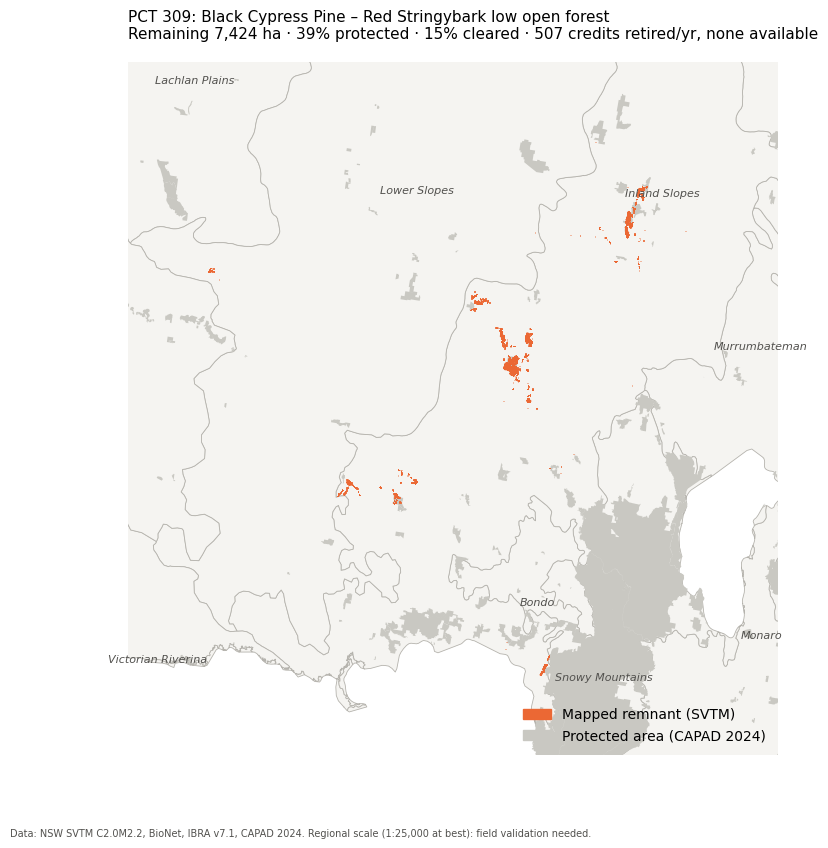

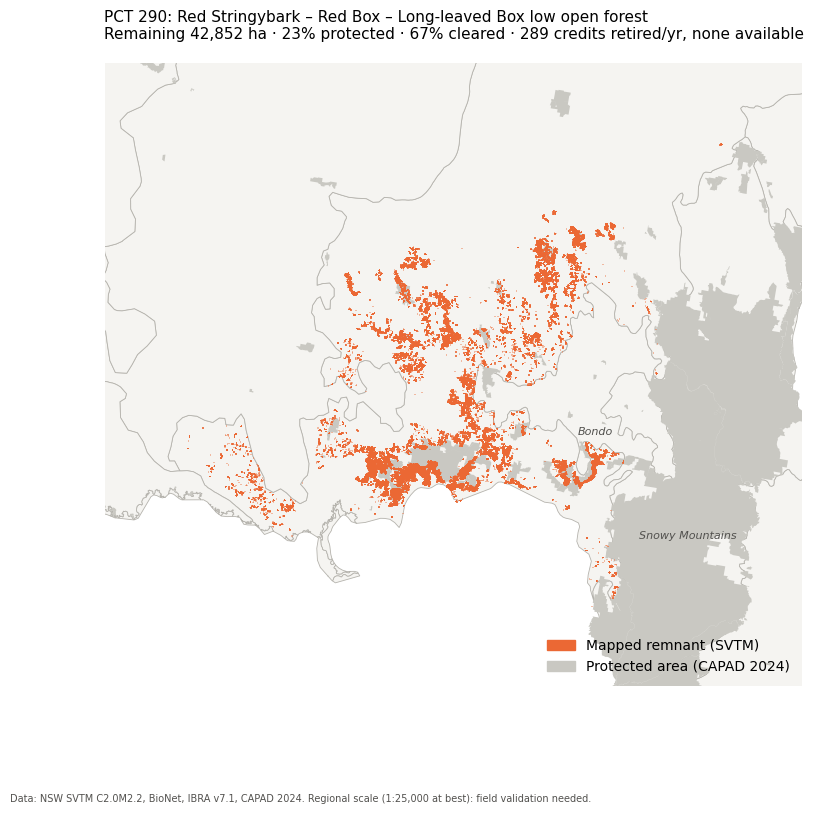

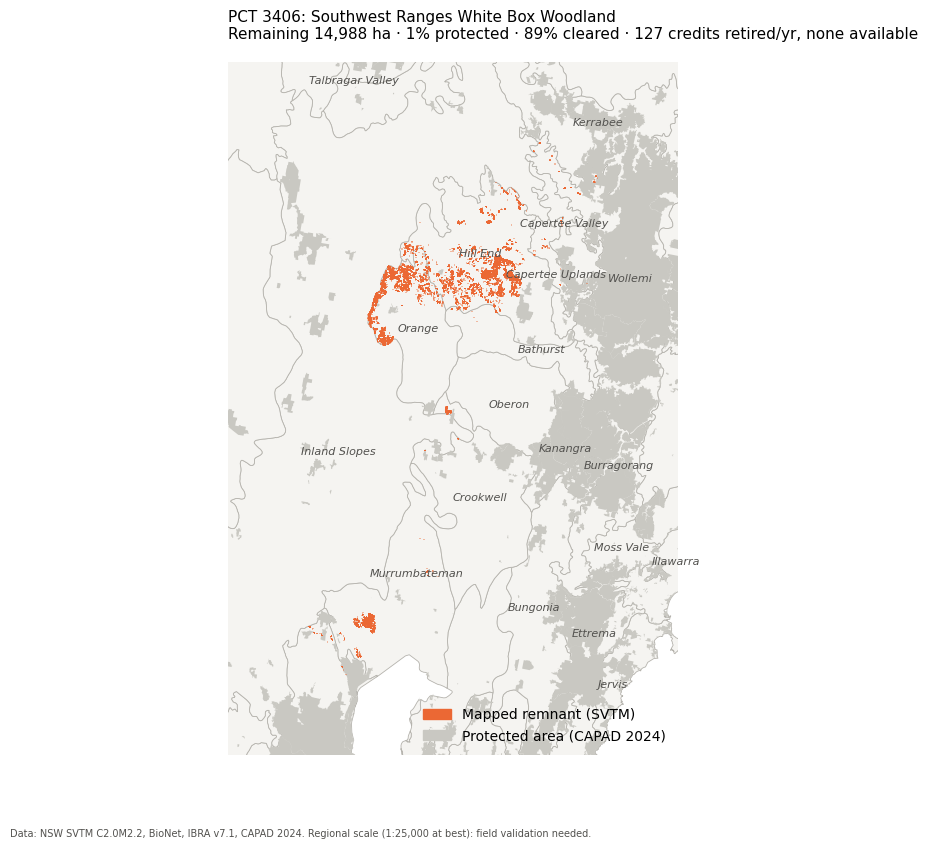

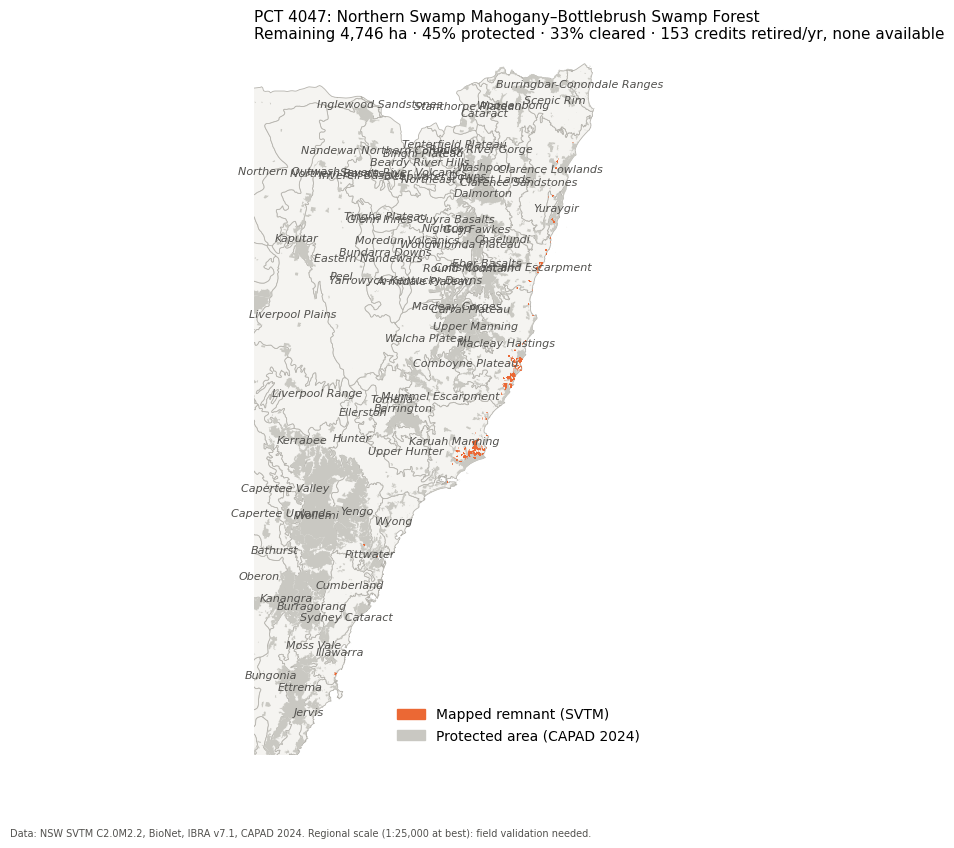

In [7]:
# STEP 22: Maps 2-5 - detail map per target PCT
names = dict(zip(pct["PCTID"], pct["PCTName"]))
short = {309: "Black Cypress Pine – Red Stringybark low open forest",
         290: "Red Stringybark – Red Box – Long-leaved Box low open forest",
         3406: "Southwest Ranges White Box Woodland",
         4047: "Northern Swamp Mahogany–Bottlebrush Swamp Forest"}

for i, p in enumerate([309, 290, 3406, 4047], start=2):
    v = veg[veg["PCTID"] == p]
    xmin, ymin, xmax, ymax = v.total_bounds
    pad = max(xmax - xmin, ymax - ymin) * 0.15
    box = (xmin - pad, ymin - pad, xmax + pad, ymax + pad)

    fig, ax = plt.subplots(figsize=(9, 9))
    ibra_nsw.plot(ax=ax, color="#f5f4f1", edgecolor="#b5b3ad", linewidth=0.6)
    capad_nsw.cx[box[0]:box[2], box[1]:box[3]].plot(ax=ax, color="#c9c8c2", edgecolor="none")
    v.plot(ax=ax, color="#eb6834", edgecolor="#eb6834", linewidth=0.6)

    for _, r in ibra_nsw.cx[box[0]:box[2], box[1]:box[3]].iterrows():
        pt = r.geometry.representative_point()
        if box[0] < pt.x < box[2] and box[1] < pt.y < box[3]:
            ax.text(pt.x, pt.y, r["SUB_NAME_7"], fontsize=8, color="#52514e", ha="center", style="italic")

    t = by_sub[by_sub["PCTID"] == p][["ha", "prot_ha"]].sum()
    ax.set_xlim(box[0], box[2]); ax.set_ylim(box[1], box[3]); ax.set_axis_off()
    ax.set_title(f"PCT {p}: {short[p]}\nRemaining {t.ha:,.0f} ha · {100*t.prot_ha/t.ha:.0f}% protected · "
                 f"{100*cleared[p]:.0f}% cleared · {demand[p]} credits retired/yr, none available",
                 fontsize=11, loc="left")
    ax.legend(handles=[mpatches.Patch(color="#eb6834", label="Mapped remnant (SVTM)"),
                       mpatches.Patch(color="#c9c8c2", label="Protected area (CAPAD 2024)")],
              loc="lower right", frameon=False)
    fig.text(0.02, 0.02, "Data: NSW SVTM C2.0M2.2, BioNet, IBRA v7.1, CAPAD 2024. "
             "Regional scale (1:25,000 at best): field validation needed.", fontsize=7, color="#52514e")
    fig.savefig(f"outputs/maps/0{i}_pct_{p}.png", dpi=200, bbox_inches="tight")
    plt.show()

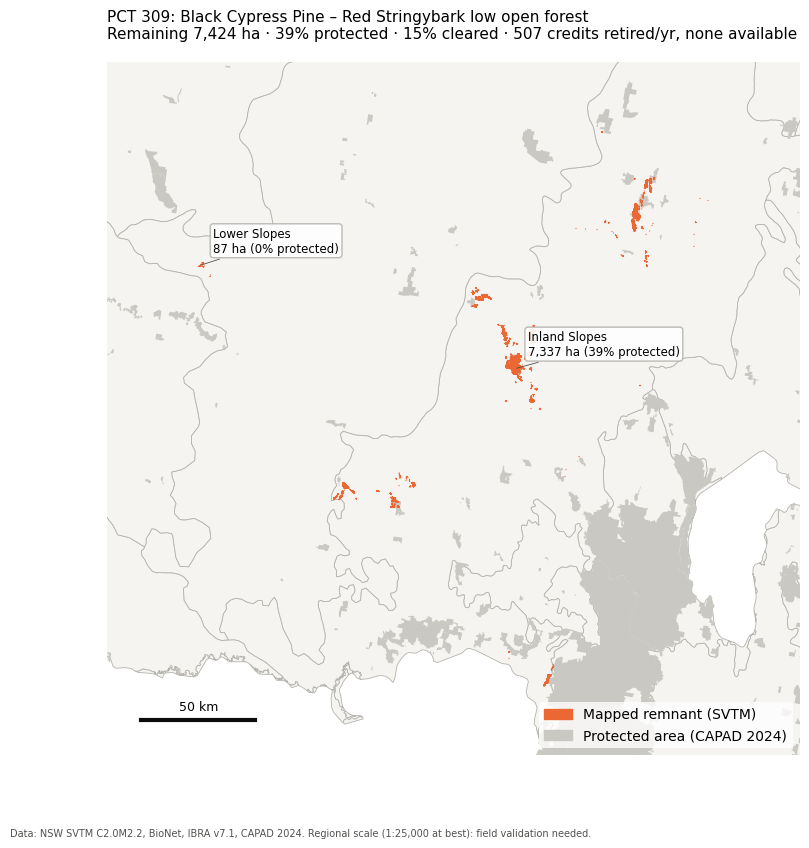

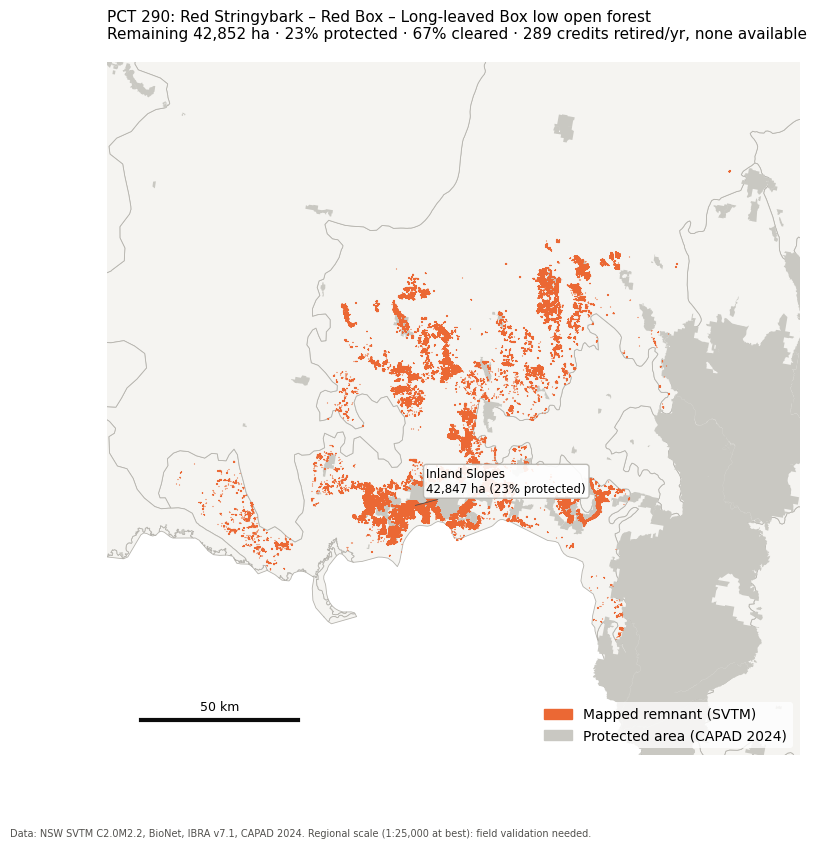

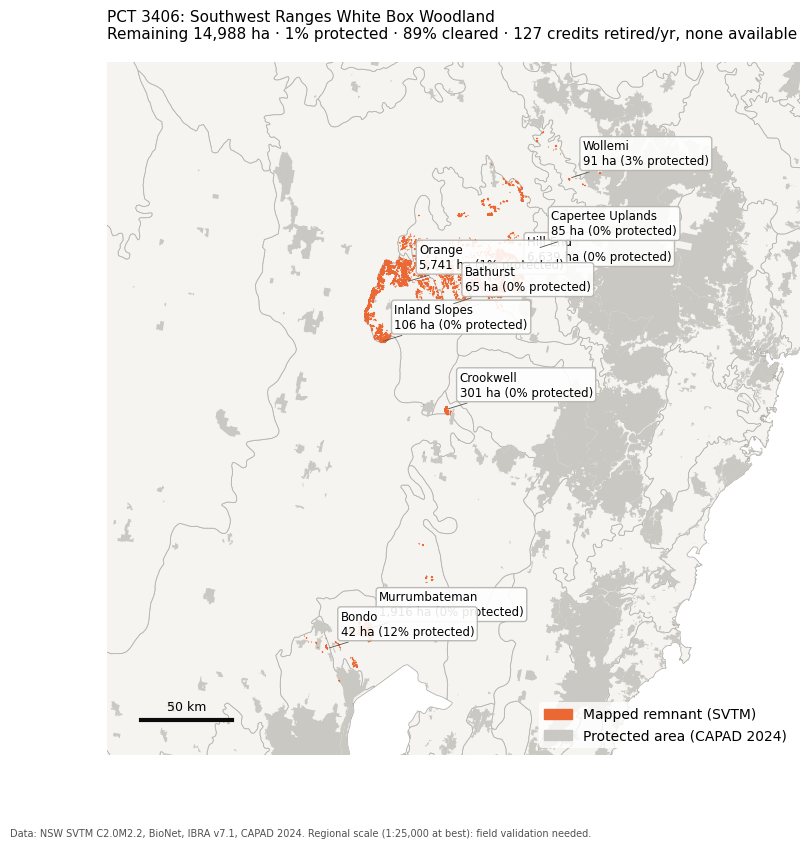

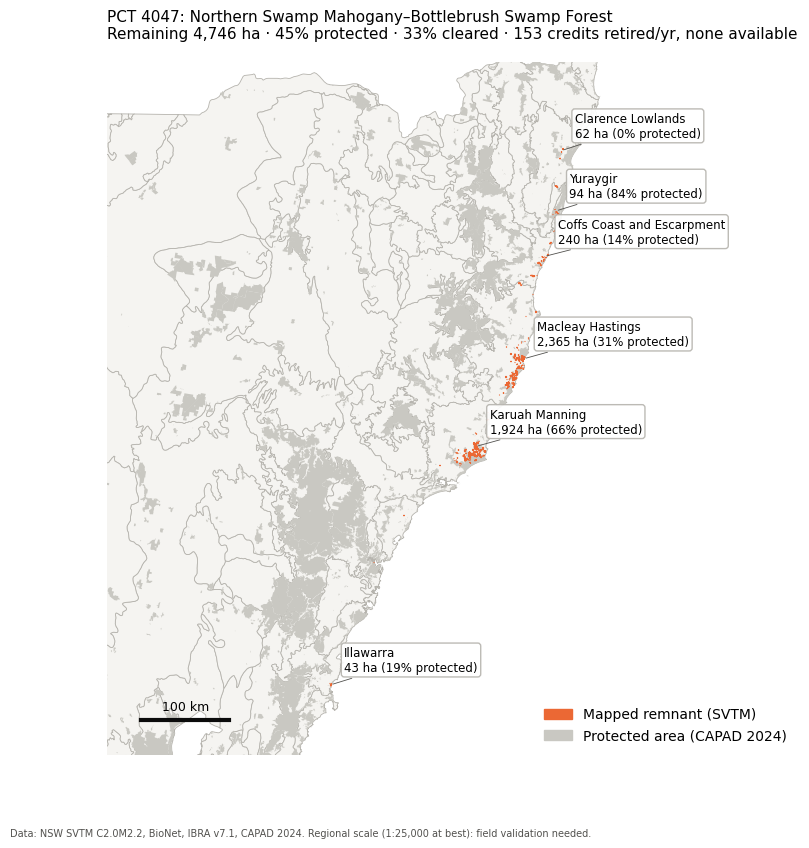

In [9]:
# STEP 22 (v2): Detail maps - label only subregions holding the PCT, add scale bar
for i, p in enumerate([309, 290, 3406, 4047], start=2):
    v = veg[veg["PCTID"] == p]
    xmin, ymin, xmax, ymax = v.total_bounds
    side = max(xmax - xmin, ymax - ymin) * 1.25
    cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
    box = (cx - side/2, cy - side/2, cx + side/2, cy + side/2)

    fig, ax = plt.subplots(figsize=(9, 9))
    ibra_nsw.plot(ax=ax, color="#f5f4f1",
                  edgecolor="#b5b3ad", linewidth=0.6)
    near = capad_nsw.cx[box[0]:box[2], box[1]:box[3]]
    near.plot(ax=ax, color="#c9c8c2", edgecolor="none")
    v.plot(ax=ax, color="#eb6834",
           edgecolor="#eb6834", linewidth=0.8)

    # label only subregions that hold this PCT
    rows = by_sub[(by_sub["PCTID"] == p) & (by_sub["unprot_ha"] >= 10)]
    for _, r in rows.iterrows():
        mask = (pieces["PCTID"] == p) & (pieces["SUB_NAME_7"] == r["SUB_NAME_7"])
        pt = pieces[mask].union_all().representative_point()
        label = f"{r['SUB_NAME_7']}\n{r['ha']:,.0f} ha ({r['pct_protected']:.0f}% protected)"
        ax.annotate(label, (pt.x, pt.y),
                    xytext=(10, 10), textcoords="offset points", fontsize=8.5,
                    bbox=dict(boxstyle="round,pad=0.25", fc="white",
                              ec="#b5b3ad", alpha=0.9),
                    arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.6))

    # scale bar
    km = 10 if side < 150_000 else 50 if side < 600_000 else 100
    sx, sy = box[0] + side * 0.05, box[1] + side * 0.05
    ax.plot([sx, sx + km * 1000], [sy, sy], color="#0b0b0b", lw=3)
    ax.text(sx + km * 500, sy + side * 0.015, f"{km} km",
            ha="center", fontsize=9)

    # title
    t = by_sub[by_sub["PCTID"] == p][["ha", "prot_ha"]].sum()
    line1 = f"PCT {p}: {short[p]}"
    line2 = f"Remaining {t.ha:,.0f} ha"
    line2 += f" · {100*t.prot_ha/t.ha:.0f}% protected"
    line2 += f" · {100*cleared[p]:.0f}% cleared"
    line2 += f" · {demand[p]} credits retired/yr, none available"
    ax.set_title(line1 + "\n" + line2, fontsize=11, loc="left")

    ax.set_xlim(box[0], box[2])
    ax.set_ylim(box[1], box[3])
    ax.set_axis_off()

    leg = [mpatches.Patch(color="#eb6834", label="Mapped remnant (SVTM)"),
           mpatches.Patch(color="#c9c8c2", label="Protected area (CAPAD 2024)")]
    ax.legend(handles=leg, loc="lower right", frameon=True,
              facecolor="white", edgecolor="none")

    note = "Data: NSW SVTM C2.0M2.2, BioNet, IBRA v7.1, CAPAD 2024. "
    note += "Regional scale (1:25,000 at best): field validation needed."
    fig.text(0.02, 0.02, note, fontsize=7, color="#52514e")

    fig.savefig(f"outputs/maps/0{i}_pct_{p}.png", dpi=200, bbox_inches="tight")
    plt.show()

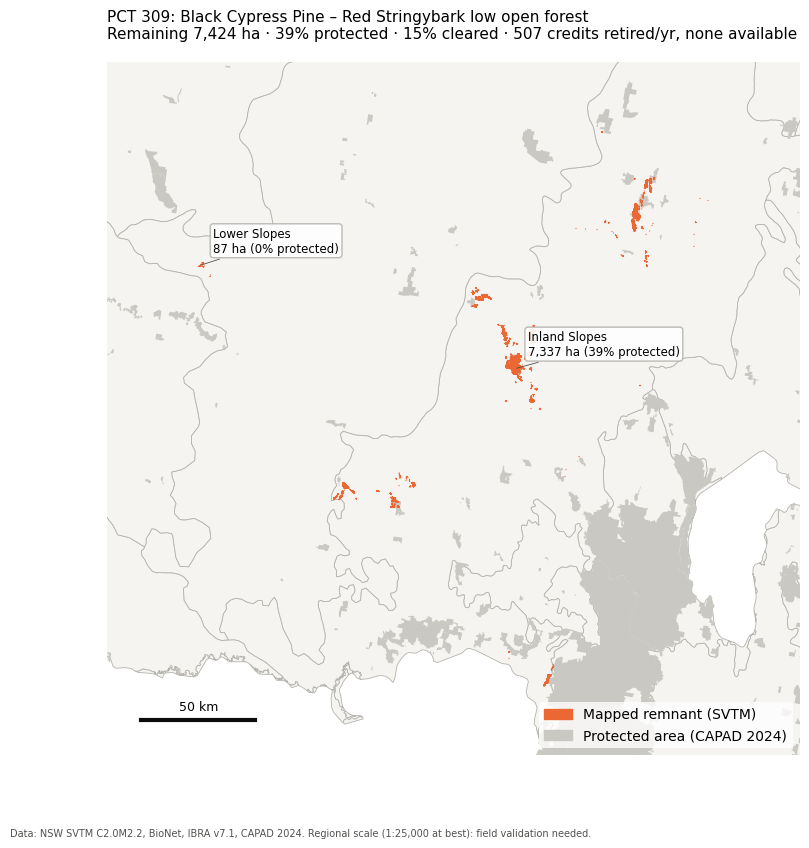

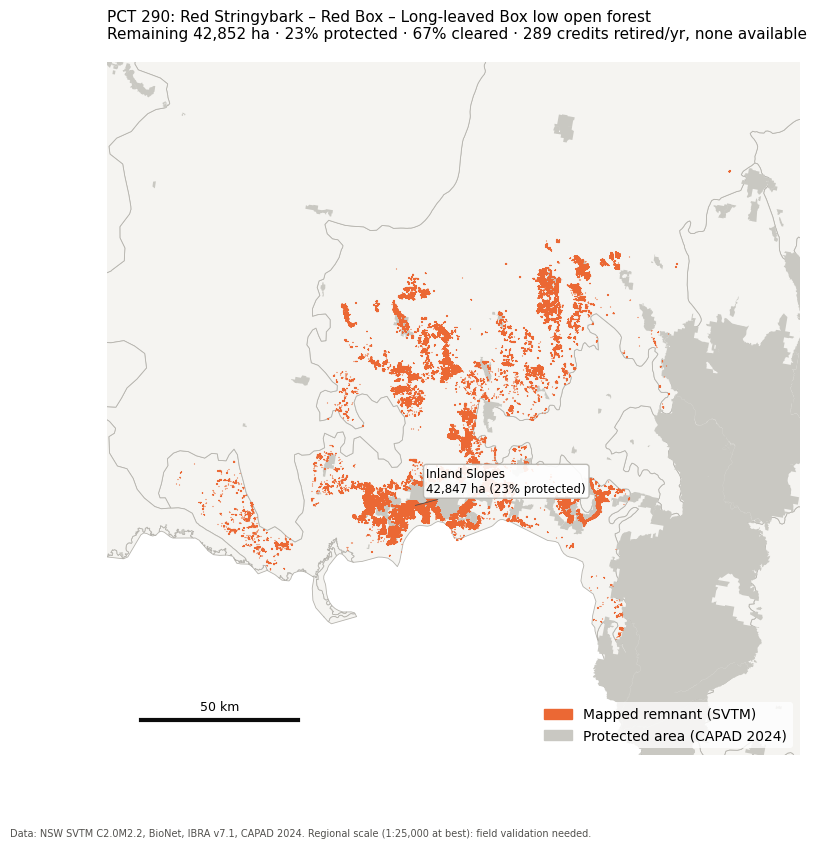

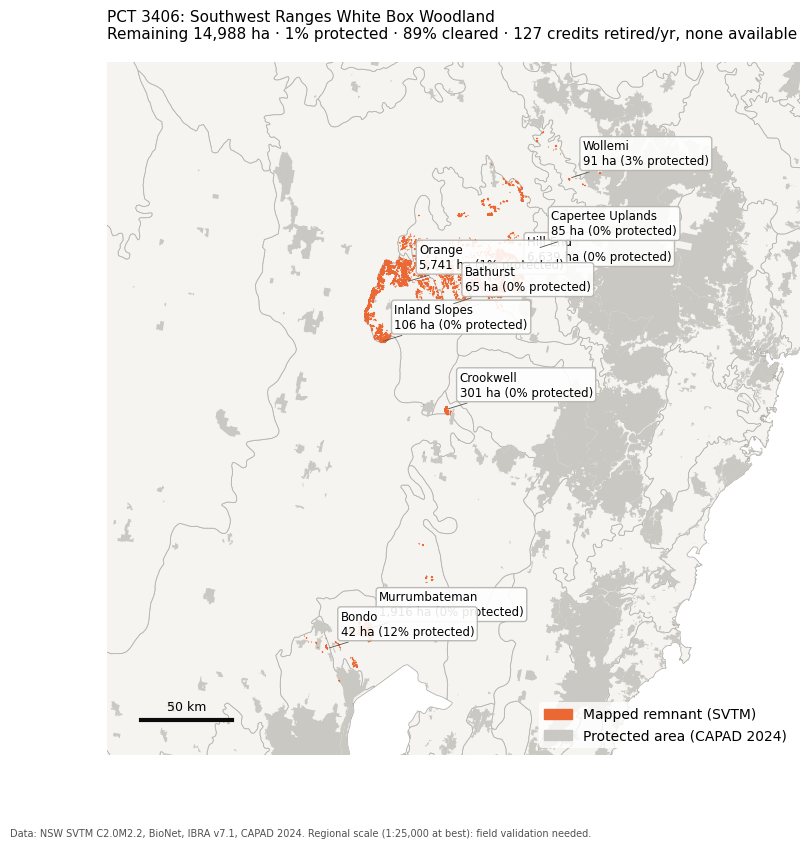

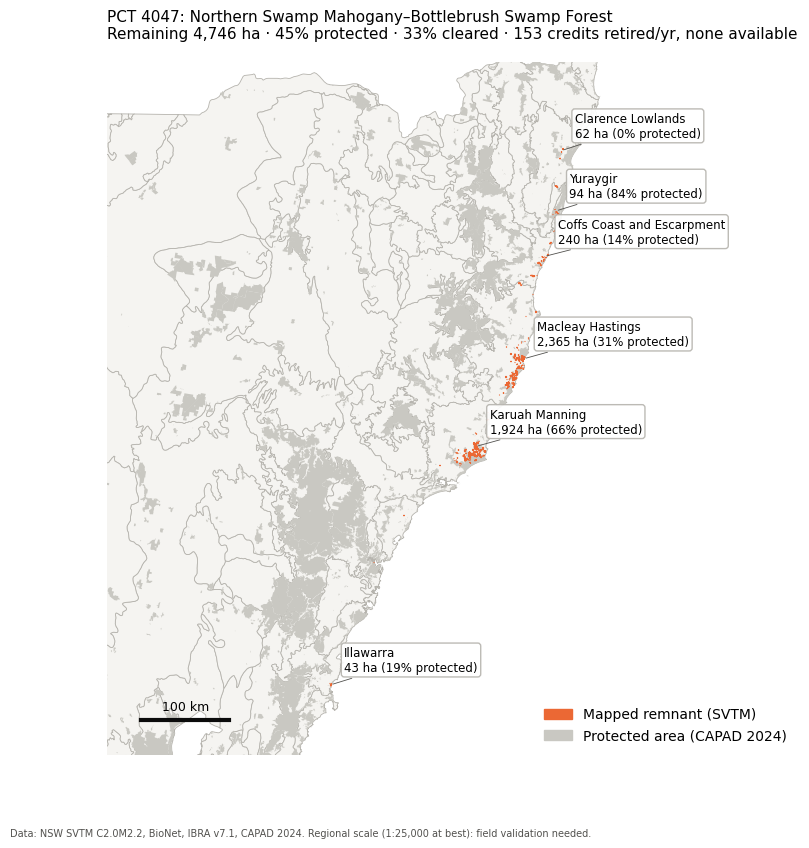

In [10]:
# STEP 22 (v2): Detail maps - label only subregions holding the PCT, add scale bar
for i, p in enumerate([309, 290, 3406, 4047], start=2):
    v = veg[veg["PCTID"] == p]
    xmin, ymin, xmax, ymax = v.total_bounds
    side = max(xmax - xmin, ymax - ymin) * 1.25
    cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
    box = (cx - side/2, cy - side/2, cx + side/2, cy + side/2)

    fig, ax = plt.subplots(figsize=(9, 9))
    ibra_nsw.plot(ax=ax, color="#f5f4f1",
                  edgecolor="#b5b3ad", linewidth=0.6)
    near = capad_nsw.cx[box[0]:box[2], box[1]:box[3]]
    near.plot(ax=ax, color="#c9c8c2", edgecolor="none")
    v.plot(ax=ax, color="#eb6834",
           edgecolor="#eb6834", linewidth=0.8)

    # label only subregions that hold this PCT
    rows = by_sub[(by_sub["PCTID"] == p) & (by_sub["unprot_ha"] >= 10)]
    for _, r in rows.iterrows():
        mask = (pieces["PCTID"] == p) & (pieces["SUB_NAME_7"] == r["SUB_NAME_7"])
        pt = pieces[mask].union_all().representative_point()
        label = f"{r['SUB_NAME_7']}\n{r['ha']:,.0f} ha ({r['pct_protected']:.0f}% protected)"
        ax.annotate(label, (pt.x, pt.y),
                    xytext=(10, 10), textcoords="offset points", fontsize=8.5,
                    bbox=dict(boxstyle="round,pad=0.25", fc="white",
                              ec="#b5b3ad", alpha=0.9),
                    arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.6))

    # scale bar
    km = 10 if side < 150_000 else 50 if side < 600_000 else 100
    sx, sy = box[0] + side * 0.05, box[1] + side * 0.05
    ax.plot([sx, sx + km * 1000], [sy, sy], color="#0b0b0b", lw=3)
    ax.text(sx + km * 500, sy + side * 0.015, f"{km} km",
            ha="center", fontsize=9)

    # title
    t = by_sub[by_sub["PCTID"] == p][["ha", "prot_ha"]].sum()
    line1 = f"PCT {p}: {short[p]}"
    line2 = f"Remaining {t.ha:,.0f} ha"
    line2 += f" · {100*t.prot_ha/t.ha:.0f}% protected"
    line2 += f" · {100*cleared[p]:.0f}% cleared"
    line2 += f" · {demand[p]} credits retired/yr, none available"
    ax.set_title(line1 + "\n" + line2, fontsize=11, loc="left")

    ax.set_xlim(box[0], box[2])
    ax.set_ylim(box[1], box[3])
    ax.set_axis_off()

    leg = [mpatches.Patch(color="#eb6834", label="Mapped remnant (SVTM)"),
           mpatches.Patch(color="#c9c8c2", label="Protected area (CAPAD 2024)")]
    ax.legend(handles=leg, loc="lower right", frameon=True,
              facecolor="white", edgecolor="none")

    note = "Data: NSW SVTM C2.0M2.2, BioNet, IBRA v7.1, CAPAD 2024. "
    note += "Regional scale (1:25,000 at best): field validation needed."
    fig.text(0.02, 0.02, note, fontsize=7, color="#52514e")

    fig.savefig(f"outputs/maps/0{i}_pct_{p}.png", dpi=200, bbox_inches="tight")
    plt.show()

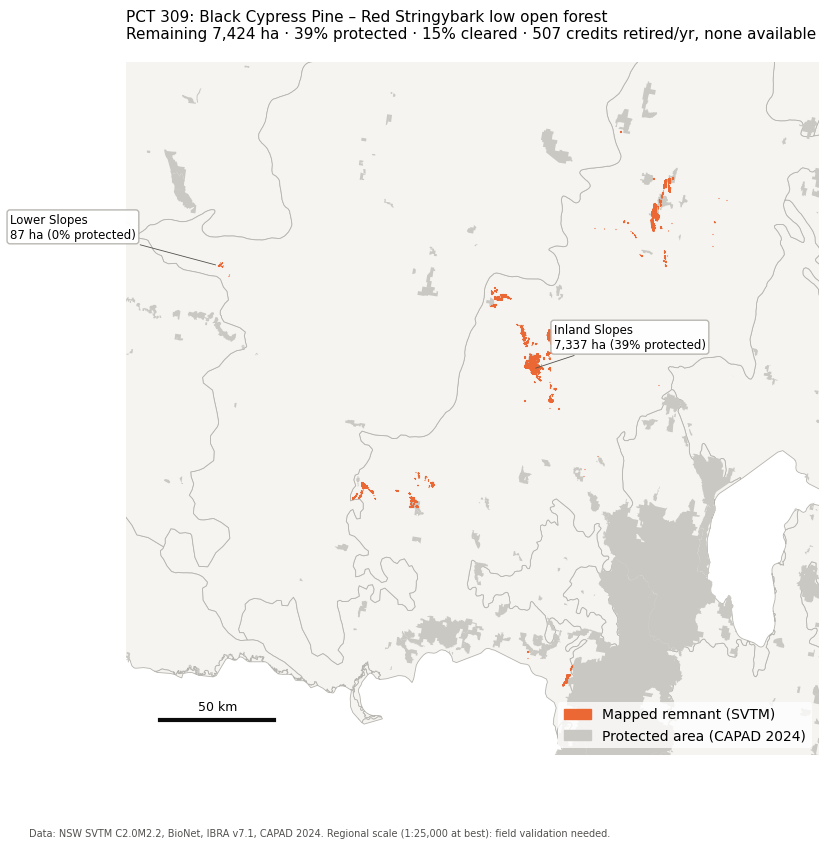

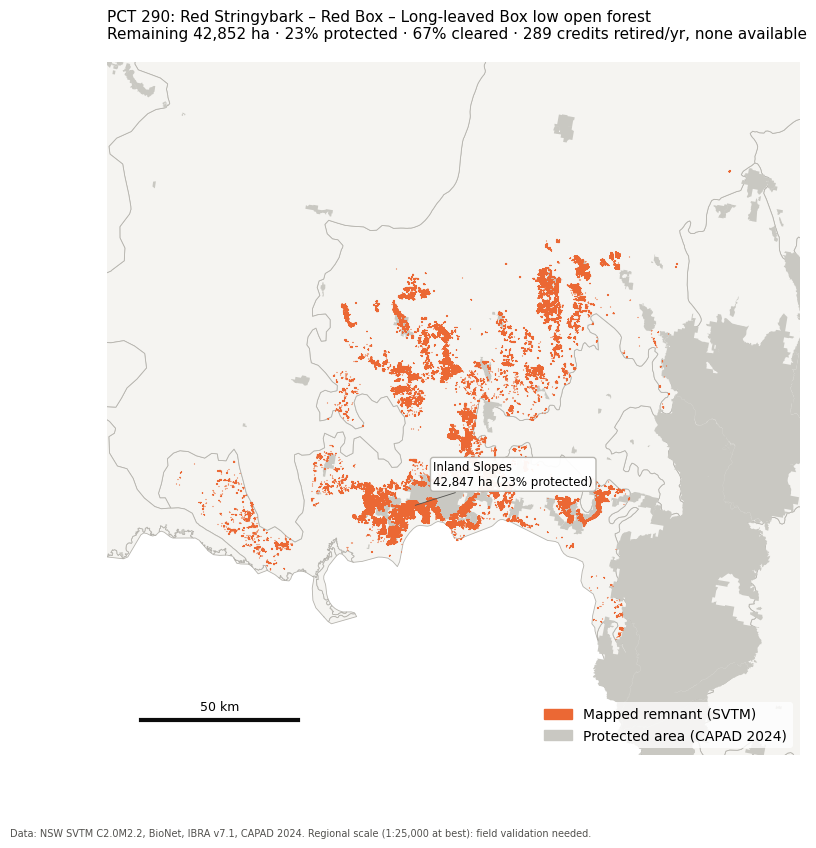

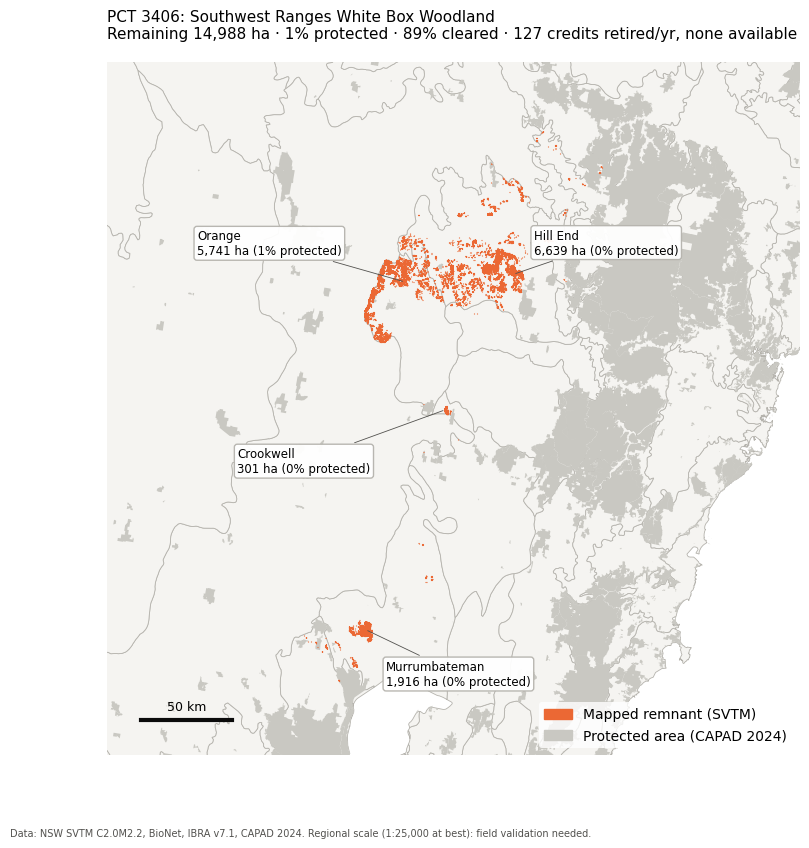

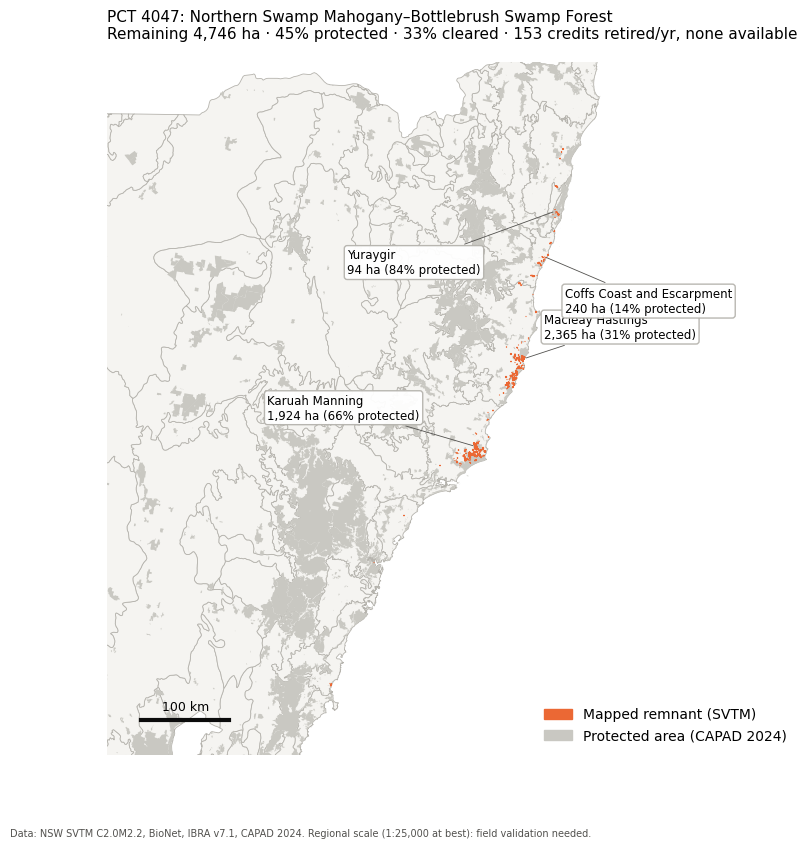

In [11]:
# STEP 22 (v3): Detail maps - top 4 labels per map, spread out
offsets = [(15, 15), (-150, 20), (15, -40), (-150, -45)]

for i, p in enumerate([309, 290, 3406, 4047], start=2):
    v = veg[veg["PCTID"] == p]
    xmin, ymin, xmax, ymax = v.total_bounds
    side = max(xmax - xmin, ymax - ymin) * 1.25
    cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
    box = (cx - side/2, cy - side/2, cx + side/2, cy + side/2)

    fig, ax = plt.subplots(figsize=(9, 9))
    ibra_nsw.plot(ax=ax, color="#f5f4f1",
                  edgecolor="#b5b3ad", linewidth=0.6)
    near = capad_nsw.cx[box[0]:box[2], box[1]:box[3]]
    near.plot(ax=ax, color="#c9c8c2", edgecolor="none")
    v.plot(ax=ax, color="#eb6834",
           edgecolor="#eb6834", linewidth=0.8)

    # label the 4 biggest subregions only
    rows = by_sub[(by_sub["PCTID"] == p) & (by_sub["unprot_ha"] >= 10)]
    rows = rows.nlargest(4, "ha").reset_index(drop=True)
    for k, r in rows.iterrows():
        mask = (pieces["PCTID"] == p) & (pieces["SUB_NAME_7"] == r["SUB_NAME_7"])
        pt = pieces[mask].union_all().representative_point()
        label = f"{r['SUB_NAME_7']}\n{r['ha']:,.0f} ha ({r['pct_protected']:.0f}% protected)"
        ax.annotate(label, (pt.x, pt.y),
                    xytext=offsets[k], textcoords="offset points", fontsize=8.5,
                    bbox=dict(boxstyle="round,pad=0.25", fc="white",
                              ec="#b5b3ad", alpha=0.95),
                    arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.6))

    # scale bar
    km = 10 if side < 150_000 else 50 if side < 600_000 else 100
    sx, sy = box[0] + side * 0.05, box[1] + side * 0.05
    ax.plot([sx, sx + km * 1000], [sy, sy], color="#0b0b0b", lw=3)
    ax.text(sx + km * 500, sy + side * 0.015, f"{km} km",
            ha="center", fontsize=9)

    # title
    t = by_sub[by_sub["PCTID"] == p][["ha", "prot_ha"]].sum()
    line1 = f"PCT {p}: {short[p]}"
    line2 = f"Remaining {t.ha:,.0f} ha"
    line2 += f" · {100*t.prot_ha/t.ha:.0f}% protected"
    line2 += f" · {100*cleared[p]:.0f}% cleared"
    line2 += f" · {demand[p]} credits retired/yr, none available"
    ax.set_title(line1 + "\n" + line2, fontsize=11, loc="left")

    ax.set_xlim(box[0], box[2])
    ax.set_ylim(box[1], box[3])
    ax.set_axis_off()

    leg = [mpatches.Patch(color="#eb6834", label="Mapped remnant (SVTM)"),
           mpatches.Patch(color="#c9c8c2", label="Protected area (CAPAD 2024)")]
    ax.legend(handles=leg, loc="lower right", frameon=True,
              facecolor="white", edgecolor="none")

    note = "Data: NSW SVTM C2.0M2.2, BioNet, IBRA v7.1, CAPAD 2024. "
    note += "Regional scale (1:25,000 at best): field validation needed."
    fig.text(0.02, 0.02, note, fontsize=7, color="#52514e")

    fig.savefig(f"outputs/maps/0{i}_pct_{p}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [12]:
# STEP 23: Inspect BioNet species sightings fields
bn = "https://data.bionet.nsw.gov.au/biosvcapp/odata/SpeciesSightings_CoreData"
r = requests.get(bn, params={"$top": 1}, timeout=120).json()
print(list(r["value"][0].keys()))

['basisOfRecord', 'collectionCode', 'dataGeneralizations', 'datasetID', 'datasetName', 'dcterms_bibliographicCitation', 'dcterms_language', 'dcterms_modified', 'dcterms_available', 'dcterms_rights', 'dcterms_rightsHolder', 'dcterms_type', 'informationWithheld', 'institutionCode', 'ownerInstitutionCode', 'BFMCS', 'botanicalDivision', 'LLS', 'floraReserve', 'geogExtent', 'IBRA', 'IBRASubregion', 'mechanicalHRDescription', 'potentialImpact', 'TSProfileID', 'reserve', 'speciesFireDescription', 'stateForest', 'vulnerability', 'associatedReferences', 'countryConservation', 'catalogNumber', 'consequence', 'establishmentMeans', 'estimateTypeCode', 'individualCount', 'individualID', 'observationType', 'occurrenceID', 'occurrenceRemarks', 'occurrenceStatus', 'otherCatalogNumbers', 'PNFFilter', 'populationName', 'recordedBy', 'recordNumber', 'reproductiveCondition', 'sex', 'stateConservation', 'status', 'protectedInNSW', 'sensitivityClass', 'migratorySpeciesAgreement', 'eventDate', 'eventID', 'ev

In [13]:
# STEP 24: Check how subregion and threat status values are written
r = requests.get(bn, params={
        "$filter": "contains(IBRASubregion,'Hill End')",
        "$select": "IBRASubregion,stateConservation,scientificName,sensitivityClass",
        "$top": 10}, timeout=120).json()
pd.DataFrame(r["value"])

,IBRASubregion,stateConservation,sensitivityClass,scientificName
0,South Eastern Highlands - Hill End,Endangered,Not Sensitive,Phascolarctos cinereus
1,South Eastern Highlands - Hill End,Endangered,Not Sensitive,Phascolarctos cinereus
2,South Eastern Highlands - Hill End,Vulnerable,Category 3,Ninox strenua
3,South Eastern Highlands - Hill End,Not Listed,Not Sensitive,Chalinolobus morio
4,South Eastern Highlands - Hill End,Not Listed,Not Sensitive,Canis lupus
5,South Eastern Highlands - Hill End,Not Listed,Not Sensitive,Canis lupus
6,South Eastern Highlands - Hill End,Vulnerable,Not Sensitive,Pachycephala inornata
7,South Eastern Highlands - Hill End,Not Listed,Not Sensitive,Macropus giganteus
8,South Eastern Highlands - Hill End,Not Listed,Not Sensitive,Pseudocheirus peregrinus
9,South Eastern Highlands - Hill End,Not Listed,Not Sensitive,Felis catus


In [14]:
# STEP 25: Threatened species (BC Act listed) per top-5 subregion - counts only
threat = "(stateConservation eq 'Vulnerable' or stateConservation eq 'Endangered' or stateConservation eq 'Critically Endangered')"
out = []
for _, row in rank.head(5).iterrows():
    name = f"{row['REG_NAME_7']} - {row['SUB_NAME_7']}"
    recs, url = [], bn
    params = {"$filter": f"IBRASubregion eq '{name}' and {threat}",
              "$select": "scientificName,stateConservation,sensitivityClass"}
    while url:
        j = requests.get(url, params=params, timeout=300).json()
        recs += j.get("value", [])
        url, params = j.get("@odata.nextLink"), None
    d = pd.DataFrame(recs)
    out.append({"rank": row["rank"], "subregion": row["SUB_NAME_7"],
                "threatened_records": len(d),
                "threatened_species": d["scientificName"].nunique() if len(d) else 0,
                "sensitive_records": (d["sensitivityClass"] != "Not Sensitive").sum() if len(d) else 0})
    print(row["SUB_NAME_7"], "done")

species = pd.DataFrame(out)
species.to_csv("data/processed/threatened_species_top5.csv", index=False)
species

Inland Slopes done
Macleay Hastings done
Hill End done
Orange done
Karuah Manning done


,rank,subregion,threatened_records,threatened_species,sensitive_records
0,1,Inland Slopes,28792,142,5084
1,2,Macleay Hastings,66708,211,7540
2,3,Hill End,2969,74,196
3,4,Orange,2794,66,599
4,5,Karuah Manning,89588,197,17745


In [16]:
# STEP 26: Zip outputs and processed data, then download to your Mac
!cd /content/drive/MyDrive/nsw-credit-opportunity-map && zip -qr /content/credit_opportunity_map_results.zip outputs data/processed
from google.colab import files
files.download("/content/credit_opportunity_map_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>